In [2]:
!pip3 install numpy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 40.2 MB/s  0:00:00

[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: /Library/Frameworks/Python.framework/Versions/3.14/bin/python3.14 -m pip install --upgrade pip


In [3]:
import numpy as np

images = np.load("BrainMRI-Classification-Registration/brain_train_image_final.npy")
labels = np.load("BrainMRI-Classification-Registration/brain_train_label.npy")

print("Image shape:", images.shape)
print("Image dtype:", images.dtype)
print("Pixel range:", images.min(), images.max())

print("Label shape:", labels.shape)
print("First 10 labels:", labels[:10])

# Handles labels shaped (N,), (N, 1), or one-hot labels (N, 3).
if labels.ndim == 2 and labels.shape[1] == 3:
    class_ids = labels.argmax(axis=1)
else:
    class_ids = labels.reshape(-1)

print("Classes and counts:", np.unique(class_ids, return_counts=True))
assert len(images) == len(labels), "Image and label counts do not match"

Image shape: (1657, 2, 100, 76)
Image dtype: float32
Pixel range: 0.0 1.0
Label shape: (1657,)
First 10 labels: [1 1 1 2 1 1 2 0 1 1]
Classes and counts: (array([0, 1, 2]), array([612, 477, 568]))


In [4]:
!pip3 install matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.3/9.3 MB 32.1 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 21.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 27.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [matplotlib]7 [matplotlib]

[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: /Library/Frameworks/Python.framework/Versions/3.14/bin/python3.14 -m pip install --upgrade pip


Matplotlib is building the font cache; this may take a moment.


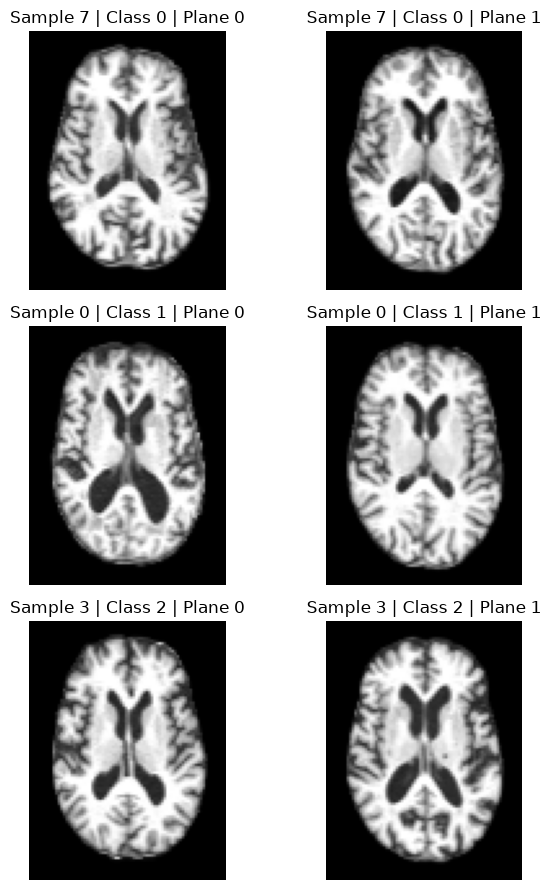

In [5]:
import matplotlib.pyplot as plt
import numpy as np

# Show one training example from each numeric class.
indices = [np.flatnonzero(labels == c)[0] for c in np.unique(labels)]

fig, axes = plt.subplots(3, 2, figsize=(7, 9))

for row, idx in enumerate(indices):
    for plane in range(2):
        axes[row, plane].imshow(
            images[idx, plane],
            cmap="gray",
            vmin=0,
            vmax=1,
        )
        axes[row, plane].set_title(
            f"Sample {idx} | Class {labels[idx]} | Plane {plane}"
        )
        axes[row, plane].axis("off")

plt.tight_layout()
plt.savefig("training_planes.png", dpi=150)
plt.show()